# Faz 4 — Modellemeye hazırlık: veri bölme ve sızıntı analizi

Bu notebook vize kriteri **7**'yi karşılar: eğitim/doğrulama/test yaklaşımı, çapraz doğrulama planı, sızıntı riskinin
değerlendirilmesi ve her modalitenin modele girecek biçimi. **Model eğitimi yoktur**; bölmeler ve girdiler finalde
kullanılmak üzere hazırlanır ve denetlenir.

**Girdi:** Faz 2 çıktıları (`temiz_cagrilar.parquet`, `seri_girdisi.npz`), Faz 1 fiyat pencereleri. Süre ~1 dk.
**Çıktı:** `veri/islenmis/bolme.parquet` (her çağrının bölmesi ve katları), `sekiller/f4_*.png`, `cikti/f4_*.csv`.

**Test ayrımı:** Test döneminin (2017+) hedeflerinden yalnız sayılar raporlanır; bütün hesaplar geliştirme döneminde yapılır.

In [1]:
import sys
import textwrap
from pathlib import Path

KOK = Path.cwd().resolve().parent
sys.path.insert(0, str(KOK))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import FuncFormatter
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, TfidfVectorizer

from src import bolme, etiket, sec
from src.istatistik import metin_komsulari

SEKIL, CIKTI, ISLENMIS = KOK / "sekiller", KOK / "cikti", KOK / "veri" / "islenmis"
SINIF_RENK = ["#6da7ec", "#2a78d6", "#104281"]
MAVI, TURUNCU, GRI, KOYU = "#2a78d6", "#eb6834", "#9a9893", "#3a3a38"
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6,
                     "axes.axisbelow": True, "figure.facecolor": "white", "axes.titlesize": 11})
pd.set_option("display.width", 170)
SINIF = etiket.SINIF_ADLARI


def kaydet(fig, ad):
    fig.savefig(SEKIL / f"{ad}.png", bbox_inches="tight")


def tr(x, nd=0):
    """Sayıyı Türkçe yazar: binlik nokta, ondalık virgül."""
    return f"{x:,.{nd}f}".replace(",", "§").replace(".", ",").replace("§", ".")


VIRGUL = FuncFormatter(lambda x, _: f"{x:g}".replace(".", ","))

temiz = pd.read_parquet(ISLENMIS / "temiz_cagrilar.parquet")
pencere = pd.read_parquet(ISLENMIS / "fiyat_pencereleri.parquet", columns=["klasor", "gun", "date"])
z = np.load(ISLENMIS / "seri_girdisi.npz", allow_pickle=True)
X, X_klasor = z["X"], z["klasor"]
print("Temiz çağrı:", len(temiz), "| seri girdisi:", X.shape, "| metin uzunluğu (kelime) en az / en çok:", temiz.n_kelime_temiz.min(), "/", temiz.n_kelime_temiz.max())

Temiz çağrı: 3000 | seri girdisi: (3000, 60, 3) | metin uzunluğu (kelime) en az / en çok: 21 / 9081


## 1. Neden rastgele (stratified) 5 kat değil?

| Bağımlılık | Veride kanıtı | Rastgele bölmede ne olurdu |
|---|---|---|
| **Şirket (birey)** | 1.055 şirket, şirket başına 1–10 çağrı (Faz 1 Şekil 8); transkript temsilleri ağırlıkla şirket kimliğini yakalıyor (Yu, Liu ve He, 2024) | Aynı şirketin çağrıları hem eğitimde hem doğrulamada olur; model şirketi "ezberleyerek" iyi görünür |
| **Zaman (olay ve piyasa)** | Çağrılar kazanç sezonlarında yığılıyor; aylık hedef ile piyasa oynaklığı ilişkili (ρ = 0,456, Faz 3 Şekil 22) | Aynı haftanın piyasa şoku eğitimde ve doğrulamada paylaşılır; geleceği tahmin etmeyen bir skor çıkar |
| **İleriye dönük hedef** | Hedef, çağrıdan sonraki 7 işlem günü | Gelecekteki çağrılardan öğrenip geçmişi "tahmin etmek" gerçek kullanımı yansıtmaz |

Bu yüzden üç düzen birlikte kullanılır:

| Düzen | Nerede | Ne ölçer | Ne için kullanılır |
|---|---|---|---|
| **Test** | 2017-01-01 → 2018-06 | Geleceğe genelleme (ve 2017+'da ilk kez görülen şirketler ayrıca) | Finalde **bir kez** nihai skor |
| **Şirket katları** (5 kat, sınıf oranı korunan, şirkete göre gruplu) | Geliştirme (≤ 2016) | Hiç görülmemiş şirkete genelleme | Model ve hiperparametre seçimi, fold'lar arası değişkenlik |
| **İleri katlar** (2016'nın 4 çeyreği sırayla doğrulama) | Geliştirme | Zamanda ileriye genelleme (bilinen şirketlerin sonraki çağrıları) | Seçilen modelin zaman kaymasına duyarlılığı |

In [2]:
b = bolme.bolme_tablosu(temiz, pencere)
b.to_parquet(ISLENMIS / "bolme.parquet", index=False)
D, T = b.bolum == "gelistirme", b.bolum == "test"
ozet = pd.DataFrame({
    "çağrı": b.bolum.value_counts(),
    "şirket": b.groupby("bolum").ticker.nunique(),
    "ilk tarih": b.groupby("bolum").tarih.min().dt.date,
    "son tarih": b.groupby("bolum").tarih.max().dt.date,
}).reindex(["gelistirme", "arindirildi", "test"]).fillna(0)
display(ozet)
yeni = set(b.loc[T, "ticker"]) - set(b.loc[D, "ticker"])
print(f"Arındırılan (hedef penceresi teste taşan) geliştirme çağrısı: {int((b.bolum == 'arindirildi').sum())}")
print(f"Son geliştirme hedef günü: {b.loc[D, 'hedef_bitis'].max().date()} | ilk test çağrı günü: {b.loc[T, 't0'].min().date()} "
      f"| aradaki işlem günü boşluğu, takvim günü: {(b.loc[T, 't0'].min() - b.loc[D, 'hedef_bitis'].max()).days}")
print(f"Testte geliştirmede hiç görülmemiş şirket: {len(yeni)} | bu şirketlerin test çağrısı: {int(b.loc[T, 'ticker'].isin(yeni).sum())}")
esik_D = etiket.esikler(b.loc[D, "v"])
test_sinif = etiket.siniflandir(b.loc[T, "v"], esik_D).astype(int)
print("Test sınıf SAYILARI (yalnız sayım, geliştirme eşikleriyle):", dict(zip(SINIF, np.bincount(test_sinif, minlength=3))))

,çağrı,şirket,ilk tarih,son tarih
bolum,,,,
gelistirme,1866.0,915.0,2015-02-25,2016-11-15
arindirildi,0.0,0.0,0,0
test,1134.0,653.0,2017-01-17,2018-06-05


Arındırılan (hedef penceresi teste taşan) geliştirme çağrısı: 0
Son geliştirme hedef günü: 2016-11-23 | ilk test çağrı günü: 2017-01-17 | aradaki işlem günü boşluğu, takvim günü: 55
Testte geliştirmede hiç görülmemiş şirket: 135 | bu şirketlerin test çağrısı: 219
Test sınıf SAYILARI (yalnız sayım, geliştirme eşikleriyle): {'düşük': np.int64(452), 'orta': np.int64(316), 'yüksek': np.int64(366)}


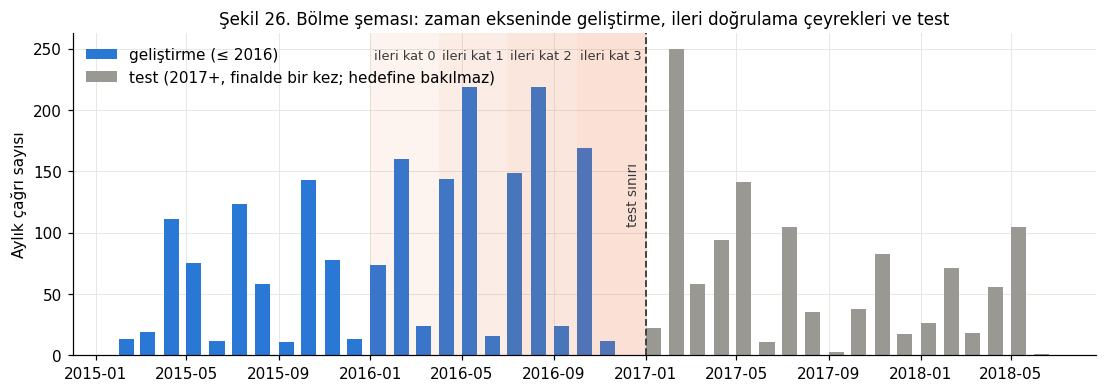

In [3]:
b["ay"] = b.t0.dt.to_period("M").dt.to_timestamp()
aylik = b[b.bolum != "arindirildi"].groupby(["ay", "bolum"]).size().unstack(fill_value=0)
fig, ax = plt.subplots(figsize=(12, 3.8))
ax.bar(aylik.index, aylik.get("gelistirme", 0), width=20, align="edge", color=MAVI, label="geliştirme (≤ 2016)")
ax.bar(aylik.index, aylik.get("test", 0), width=20, align="edge", color=GRI, label="test (2017+, finalde bir kez; hedefine bakılmaz)")
for k, q in enumerate(["2016Q1", "2016Q2", "2016Q3", "2016Q4"]):
    bas = pd.Period(q).start_time
    ax.axvspan(bas, pd.Period(q).end_time, color=TURUNCU, alpha=0.08 + 0.04 * k, lw=0)
    ax.text(bas + pd.Timedelta(days=45), ax.get_ylim()[1] * 0.92, f"ileri kat {k}", ha="center", fontsize=8.5, color=KOYU)
ax.axvline(pd.Timestamp("2017-01-01"), color=KOYU, lw=1.2, ls="--")
ax.text(pd.Timestamp("2016-12-24"), ax.get_ylim()[1] * 0.5, "test sınırı", fontsize=9, color=KOYU, ha="right", va="center", rotation=90)
ax.set_ylabel("Aylık çağrı sayısı")
ax.legend(frameon=False, loc="upper left")
ax.set_title("Şekil 26. Bölme şeması: zaman ekseninde geliştirme, ileri doğrulama çeyrekleri ve test")
kaydet(fig, "f4_01_bolme_semasi")
plt.show()

**Ne gözlendi:** Geliştirme dönemi 2015-02 – 2016-12 (1.866 çağrı, 915 şirket), test dönemi 2017-01 – 2018-06 (1.134 çağrı,
653 şirket). Hiçbir geliştirme çağrısının hedef penceresi test dönemine taşmıyor (arındırılan çağrı yok); son geliştirme hedef
günü ile ilk test çağrısı arasında doğal bir boşluk var. Testteki 653 şirketin 135'i geliştirmede hiç görülmemiş.

**Neden önemli:** Test, geliştirme döneminden zamanca tamamen ayrı ve sonra geliyor; geliştirme etiketleri test dönemine ait
hiçbir fiyat gününü kullanmıyor. 135 yeni şirket, testte "hem gelecek hem yeni şirket" alt kümesinin ayrıca
raporlanabilmesini sağlıyor.

**Sonraki aşamaya etkisi:** Final modeli yalnız geliştirme verisiyle eğitilip seçilecek; test skoru bir kez hesaplanacak ve
tüm test ile yeni şirket alt kümesi için ayrı verilecek.

## 2. Şirket katları (5 kat, sınıf oranı korunan, şirkete göre gruplu)

`StratifiedGroupKFold`: bir şirketin bütün çağrıları aynı kattadır; katların sınıf oranı mümkün olduğunca korunur.
**Etiket eşikleri her katta yalnız o katın eğitim kısmından** hesaplanır; doğrulama etiketleri bu eşiklerle atanır.

In [4]:
satirlar, kat_sinif = [], {}
for k in range(bolme.KAT_SAYISI):
    egit, dog = bolme.sirket_kati(b, k)
    y_e, esik = bolme.kat_etiketleri(b, egit, egit)
    y_d, _ = bolme.kat_etiketleri(b, egit, dog)
    ortak = set(b.loc[egit, "ticker"]) & set(b.loc[dog, "ticker"])
    kat_sinif[k] = (y_e, y_d)
    satirlar.append({"kat": k, "eğitim": int(egit.sum()), "doğrulama": int(dog.sum()), "doğrulama şirketi": b.loc[dog, "ticker"].nunique(),
                     "ortak şirket": len(ortak), "eşik 1": esik[0], "eşik 2": esik[1],
                     **{f"doğ. {SINIF[c]}": int((y_d == c).sum()) for c in range(3)}})
katlar = pd.DataFrame(satirlar)
katlar.to_csv(CIKTI / "f4_sirket_katlari.csv", index=False)
assert (katlar["ortak şirket"] == 0).all(), "eğitim ve doğrulama şirketleri ayrık olmalı"
assert katlar["doğrulama"].sum() == int(D.sum()), "her geliştirme çağrısı tam bir kez doğrulamada"
print(f"Geliştirme döneminin tamamından eşikler: {np.round(esik_D, 4)} | kat eşiklerinin aralığı: "
      f"{katlar['eşik 1'].min():.4f}–{katlar['eşik 1'].max():.4f} ve {katlar['eşik 2'].min():.4f}–{katlar['eşik 2'].max():.4f}")
katlar.round(4)

Geliştirme döneminin tamamından eşikler: [-4.1394 -3.608 ] | kat eşiklerinin aralığı: -4.1401–-4.1376 ve -3.6084–-3.6075


,kat,eğitim,doğrulama,doğrulama şirketi,ortak şirket,eşik 1,eşik 2,doğ. düşük,doğ. orta,doğ. yüksek
0,0,1491,375,187,0,-4.1394,-3.6076,125,125,125
1,1,1494,372,180,0,-4.1376,-3.6080,126,122,124
2,2,1492,374,190,0,-4.1387,-3.6075,125,125,124
3,3,1493,373,180,0,-4.1401,-3.6084,124,124,125
4,4,1494,372,178,0,-4.1399,-3.6081,124,124,124


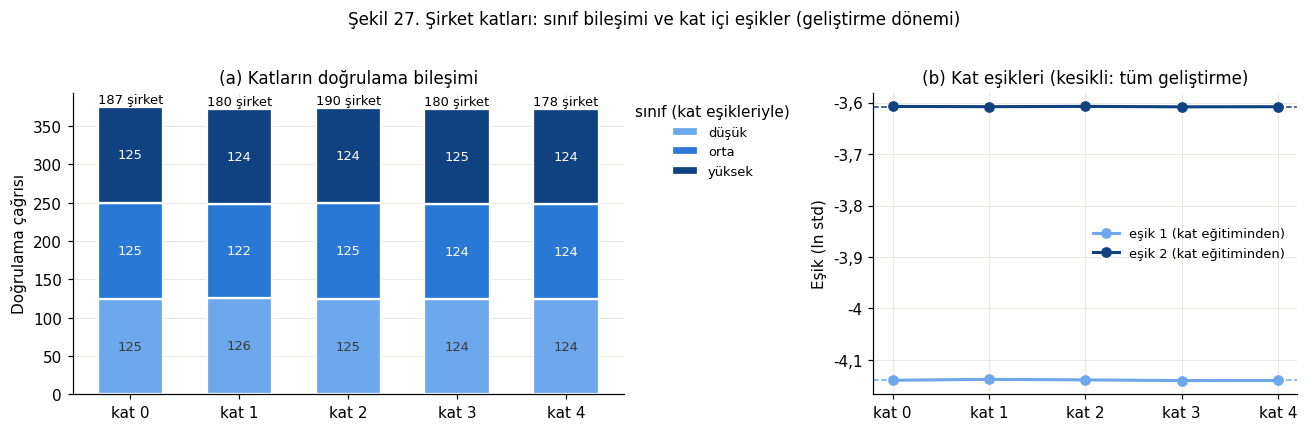

In [5]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [1.3, 1]})
alt = np.zeros(bolme.KAT_SAYISI)
for c in range(3):
    deger = katlar[f"doğ. {SINIF[c]}"].to_numpy()
    a1.bar(katlar.kat, deger, bottom=alt, color=SINIF_RENK[c], width=0.6, label=SINIF[c], edgecolor="white", linewidth=1.5)
    for k, (bb, h) in enumerate(zip(alt, deger)):
        a1.text(k, bb + h / 2, str(h), ha="center", va="center", fontsize=8.5, color="white" if c > 0 else KOYU)
    alt += deger
for k, r in katlar.iterrows():
    a1.text(k, alt[k] + 5, f"{int(r['doğrulama şirketi'])} şirket", ha="center", fontsize=8.5)
a1.set_xticks(katlar.kat, [f"kat {k}" for k in katlar.kat])
a1.set_ylabel("Doğrulama çağrısı")
a1.legend(title="sınıf (kat eşikleriyle)", frameon=False, bbox_to_anchor=(1.0, 1.0), loc="upper left", fontsize=8.5)
a1.set_title("(a) Katların doğrulama bileşimi")
for i, (ad, renk) in enumerate([("eşik 1", SINIF_RENK[0]), ("eşik 2", SINIF_RENK[2])]):
    a2.plot(katlar.kat, katlar[ad], marker="o", color=renk, lw=2, label=f"{ad} (kat eğitiminden)")
    a2.axhline(esik_D[i], color=renk, ls="--", lw=1)
a2.set_xticks(katlar.kat, [f"kat {k}" for k in katlar.kat])
a2.set_ylabel("Eşik (ln std)")
a2.yaxis.set_major_formatter(VIRGUL)
a2.legend(frameon=False, fontsize=8.5)
a2.set_title("(b) Kat eşikleri (kesikli: tüm geliştirme)")
fig.suptitle("Şekil 27. Şirket katları: sınıf bileşimi ve kat içi eşikler (geliştirme dönemi)", y=1.02, fontsize=11)
fig.tight_layout()
kaydet(fig, "f4_02_sirket_katlari")
plt.show()

## 3. İleri (zaman) katları

2016'nın her çeyreği sırayla doğrulama olur; eğitim, o çeyrekten önceki bütün geliştirme çağrılarıdır (genişleyen pencere).
Hedef penceresi doğrulamanın ilk gününe ulaşan eğitim çağrıları atılır (arındırma).

In [6]:
satirlar = []
for k in range(4):
    egit, dog = bolme.ileri_kat(b, k)
    y_d, esik = bolme.kat_etiketleri(b, egit, dog)
    once = (b.bolum == "gelistirme") & (b.t0 < b.loc[dog, "t0"].min())
    satirlar.append({"ileri kat": k, "doğrulama çeyreği": b.loc[dog, "ceyrek"].iloc[0], "eğitim": int(egit.sum()),
                     "arındırılan": int(once.sum() - egit.sum()), "doğrulama": int(dog.sum()),
                     "doğrulamada eğitimde görülmüş şirket %": round(100 * b.loc[dog, "ticker"].isin(set(b.loc[egit, "ticker"])).mean(), 1),
                     "eşik 1": esik[0], "eşik 2": esik[1], **{f"doğ. {SINIF[c]}": int((y_d == c).sum()) for c in range(3)}})
ileri = pd.DataFrame(satirlar)
ileri.to_csv(CIKTI / "f4_ileri_katlar.csv", index=False)
ileri.round(4)

,ileri kat,doğrulama çeyreği,eğitim,arındırılan,doğrulama,doğrulamada eğitimde görülmüş şirket %,eşik 1,eşik 2,doğ. düşük,doğ. orta,doğ. yüksek
0,0,2016Q1,656,0,258,60.5,-4.1353,-3.6334,33,89,136
1,1,2016Q2,913,1,379,48.5,-4.0480,-3.5424,157,106,116
2,2,2016Q3,1293,0,392,70.4,-4.0797,-3.5541,170,123,99
3,3,2016Q4,1679,6,181,71.8,-4.1244,-3.5865,80,61,40


**Ne gözlendi:** Şirket katlarında eğitim ile doğrulama şirketleri tamamen ayrık (her katta ortak şirket 0) ve her
geliştirme çağrısı tam bir kez doğrulamada yer alıyor. Kat eşikleri birbirine ve tüm geliştirme eşiklerine çok yakın;
katların sınıf bileşimi dengeli. İleri katlarda eğitim kümesi her adımda büyüyor; doğrulama çeyreğindeki şirketlerin
büyük kısmı eğitimde daha önce görülmüş (bilinen şirketlerin sonraki çağrıları senaryosu).

**Neden önemli:** Şirket katları "yeni şirket", ileri katlar "gelecek çeyrek" genellemesini ölçüyor; ikisi farklı soruları
yanıtladığı için birlikte raporlanacak. Eşiklerin katlar arasında az değişmesi, etiket tanımının bölmeye karşı kararlı
olduğunu gösteriyor.

**Sonraki aşamaya etkisi:** Final modeli için hiperparametreler şirket katlarının ortalamasıyla seçilecek; seçilen model
ileri katlarda da raporlanacak. Her katta eşik, ölçekleme ve metin sözlüğü yeniden ve yalnız eğitim kısmından öğrenilecek.

## 4. Sızıntı denetimi

In [7]:
# (a) Aynı şirketin farklı kodlarla gelmesi: SEC şirket kimliği (CIK) üzerinden
cik = sec.sirket_bilgisi(b.ticker.unique()).set_index("ticker").cik
b["cik"] = b.ticker.map(cik)
cok_kod = b.dropna(subset=["cik"]).groupby("cik").ticker.nunique()
print(f"(a) Birden çok koda sahip şirket (CIK): {int((cok_kod > 1).sum())} | CIK'i bilinmeyen geliştirme çağrısı: "
      f"%{100 * b.loc[D, 'cik'].isna().mean():.1f} (bunlar kontrol edilemiyor)")

# (b) İki modalite aynı satırda: metin tablosu, seri dizisi ve bölme tablosu aynı çağrı sırasında
assert (temiz.klasor.to_numpy() == X_klasor).all() and (b.klasor.to_numpy() == X_klasor).all()
print("(b) Metin, fiyat dizisi ve bölme tablosu aynı çağrı sırasında: evet → bir çağrının iki modalitesi hep aynı katta")

# (c) Zaman bağımlılığı: şirket katlarında doğrulama çağrısının ±3 gün içinde başka bir eğitim çağrısı var mı?
pay = []
for k in range(bolme.KAT_SAYISI):
    egit, dog = bolme.sirket_kati(b, k)
    e_t = np.sort(b.loc[egit, "t0"].to_numpy())
    d_t = b.loc[dog, "t0"].to_numpy()
    sayi = np.searchsorted(e_t, d_t + np.timedelta64(3, "D"), side="right") - np.searchsorted(e_t, d_t - np.timedelta64(3, "D"))
    pay.append(np.mean(sayi > 0))
print(f"(c) Şirket katlarında, ±3 gün içinde aynı dönemden bir eğitim çağrısı bulunan doğrulama çağrısı: %{100 * np.mean(pay):.1f} "
      f"(kat aralığı %{100 * min(pay):.1f}–%{100 * max(pay):.1f})")

(a) Birden çok koda sahip şirket (CIK): 0 | CIK'i bilinmeyen geliştirme çağrısı: %22.3 (bunlar kontrol edilemiyor)
(b) Metin, fiyat dizisi ve bölme tablosu aynı çağrı sırasında: evet → bir çağrının iki modalitesi hep aynı katta
(c) Şirket katlarında, ±3 gün içinde aynı dönemden bir eğitim çağrısı bulunan doğrulama çağrısı: %99.5 (kat aralığı %99.2–%100.0)


(d) Başka kattaki en benzer metin (kosinüs): %50: 0.224, %90: 0.319, %99: 0.393, %100: 0.532
    20160803_OHI ↔ 20160526_CHS: 0.532 | Thank you. Thanks, Andrew. Thanks, everyone, for joining the call this morning. [...] || Thank you. Thank you, Andrew. That concludes our call for this morning. Thank you [...]
    20160526_CHS ↔ 20160803_OHI: 0.532 | Thank you. Thank you, Andrew. That concludes our call for this morning. Thank you [...] || Thank you. Thanks, Andrew. Thanks, everyone, for joining the call this morning. [...]
    20150423_HSY ↔ 20160803_OHI: 0.444 | Thank you very much for your time today. I'll be available for any follow-up [...] || Thank you. Thanks, Andrew. Thanks, everyone, for joining the call this morning. [...]
    0,5'ten benzer çift: 2 | 0,8'den benzer: 0


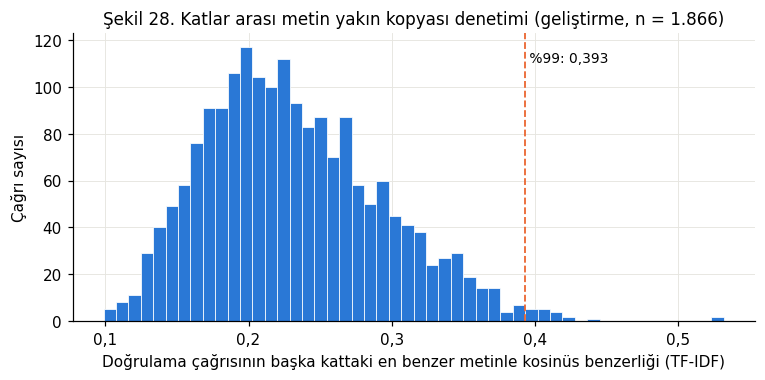

In [8]:
# (d) Metin yakın kopyası: her doğrulama çağrısının, başka katlardaki eğitim çağrılarına en yüksek metin benzerliği
dk = b[D].reset_index(drop=True)
metinler = [" ".join(s) for s in temiz.set_index("klasor").loc[dk.klasor, "cumleler_temiz"]]
_, Bm, _, _ = metin_komsulari(metinler, dk.ticker, K=1)        # aynı şirket çiftleri zaten -inf
ayni_kat = dk.kat.to_numpy()[:, None] == dk.kat.to_numpy()[None, :]
Bm[ayni_kat] = -np.inf
en_yuksek = Bm.max(axis=1)
print("(d) Başka kattaki en benzer metin (kosinüs): " + ", ".join(f"%{q}: {np.percentile(en_yuksek, q):.3f}" for q in (50, 90, 99, 100)))
i_max = np.argsort(-en_yuksek)[:3]
for i in i_max:
    j = int(np.argmax(Bm[i]))
    print(f"    {dk.klasor[i]} ↔ {dk.klasor[j]}: {en_yuksek[i]:.3f} | {textwrap.shorten(metinler[i], 90)} || {textwrap.shorten(metinler[j], 90)}")
print(f"    0,5'ten benzer çift: {int((en_yuksek > 0.5).sum())} | 0,8'den benzer: {int((en_yuksek > 0.8).sum())}")

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.hist(en_yuksek, bins=50, color=MAVI, edgecolor="white", linewidth=0.5)
ax.axvline(np.percentile(en_yuksek, 99), color=TURUNCU, ls="--", lw=1.2)
ax.text(np.percentile(en_yuksek, 99), ax.get_ylim()[1] * 0.9, f" %99: {tr(np.percentile(en_yuksek, 99), 3)}", fontsize=9)
ax.set_xlabel("Doğrulama çağrısının başka kattaki en benzer metinle kosinüs benzerliği (TF-IDF)")
ax.set_ylabel("Çağrı sayısı")
ax.xaxis.set_major_formatter(VIRGUL)
ax.set_title(f"Şekil 28. Katlar arası metin yakın kopyası denetimi (geliştirme, n = {tr(len(dk))})")
kaydet(fig, "f4_03_metin_kopya")
plt.show()

**Ne gözlendi:** (a) SEC kimliği bilinen şirketlerin hiçbiri birden çok borsa koduyla gelmiyor; geliştirme çağrılarının %22,3'ünün kimliği bilinmediği için bu kısım kontrol edilemiyor. (b) Metin tablosu, fiyat dizisi ve bölme tablosu aynı çağrı sırasında. (c) Şirket katlarında doğrulama çağrılarının %99,5'inin ±3 gün içinde eğitimde başka bir şirketin çağrısı var (katlar arasında %99,2–%100). (d) Bir doğrulama çağrısının başka kattaki en benzer metinle benzerliği medyanda 0,224, %99'luk dilimde 0,393, en fazla 0,532; 0,5'i geçen yalnız 2 çağrı var ve bunlar kapanış kalıbı ("Thank you, Andrew. That concludes our call"), 0,8'i geçen yok.

**Neden önemli:** Şirket katları birey (şirket) sızıntısını tamamen kesiyor ama zaman bağımlılığını kesmiyor: hemen her doğrulama çağrısı, eğitimde aynı haftadan çağrılarla birlikte. Bu, şirket katlarının skorunun aynı dönemin piyasa havasını paylaştığı için iyimser çıkabileceği anlamına gelir; ileri katlar ve zamanca ayrı test kümesi bu yüzden zorunlu. Metinde içerik kopyası yok; en yüksek benzerlikler kısa kapanış cümlelerinden.

**Sonraki aşamaya etkisi:** Final raporunda şirket katlarının skoru tek başına verilmeyecek; ileri katlar ve test skoruyla birlikte okunacak. CIK'i bilinmeyen çağrılar için aynı şirketin farklı kodlarla gelme riski sınırlılık olarak yazılacak.

| Risk türü (hocanın listesi) | Bu projede karşılığı | Ölçüm | Durum |
|---|---|---|---|
| Birey | Aynı şirketin çağrıları | Şirket katlarında eğitim–doğrulama ortak şirket sayısı | 0 (her katta) |
| Birey | Aynı şirketin farklı borsa kodları | SEC CIK başına kod sayısı | Çoklu kodlu şirket yok; CIK'i bilinmeyenler kontrol edilemiyor (sınırlılık) |
| Olay | Bir çağrının iki modalitesi | Metin, dizi ve bölme tablosunun çağrı sırası | Aynı satır → aynı kat |
| Olay | Aynı çağrının iki kaydı | Faz 2 tekrar kontrolü + (d) katlar arası en yüksek metin benzerliği | Kopya yok |
| Kaynak | Ortak kalıp metin (yasal uyarı, açılış) | (d) en benzer çiftler | Benzerlik kalıp cümlelerden; içerik kopyası değil |
| Zaman | Aynı haftanın piyasa şoku | (c) doğrulama çağrılarının ±3 gün içinde eğitim çağrısı payı | Şirket katlarında yüksek → bu yüzden ileri katlar ve zaman testi var |
| Zaman | Hedef penceresinin teste taşması | Arındırma | 0 çağrı; geliştirme ile test arasında boşluk |
| Etiket | Eşiklerin doğrulama/testten öğrenilmesi | Kat eşikleri yalnız kat eğitiminden | Uygulandı |
| Girdi | Hedef gününün girdiye karışması | Girdi gün −1'de biter (Faz 1), test `tests/` altında | Uygulandı |

## 5. Modele uygun veri yapısı

| Modalite / alan | Biçim | Boyut ve tür | Katta öğrenilen (yalnız eğitim kısmından) |
|---|---|---|---|
| Metin | Temizlenmiş cümle listesi (`cumleler_temiz`) | 3.000 çağrı; değişken uzunluk (21–9.081 kelime) | TF-IDF sözlüğü / dil modeli için parçalama ayarları |
| Fiyat dizisi | `X[i]` = 60 gün × 3 kanal (getiri, göreli log hacim, gün içi aralık) | (3.000, 60, 3), float32 | Kanal başına ortalama ve std (standartlaştırma) |
| Piyasa bağlamı (isteğe bağlı) | `piyasa_once` (SPY, gün −20..−1) | skaler | Ölçekleme |
| Etiket | `v` (sürekli) ve sınıf (0/1/2) | 3.000 | Sınıf eşikleri |
| Eşleşme bilgisi | `klasor` (YYYYMMDD_TICKER), `ticker`, `t0`, `bolum`, `kat`, `ileri_kat` | `bolme.parquet` | — |

In [9]:
# Kat içi standartlaştırma: kanal istatistikleri yalnız kat-0 eğitiminden, doğrulamaya aynen uygulanır
egit0, dog0 = bolme.sirket_kati(b, 0)
ort = X[egit0.to_numpy()].mean(axis=(0, 1))
ss = X[egit0.to_numpy()].std(axis=(0, 1))
Xd = (X[dog0.to_numpy()] - ort) / ss
print("Kat 0 eğitim kanal ortalaması:", np.round(ort, 5), "| std:", np.round(ss, 5))
print("Bu istatistiklerle standartlaştırılan kat 0 DOĞRULAMA kanalları → ortalama:", np.round(Xd.mean(axis=(0, 1)), 3),
      "| std:", np.round(Xd.std(axis=(0, 1)), 3), "(tam 0/1 değil: doğrulama istatistiği kullanılmadı)")

# Kat içi metin sözlüğü: TF-IDF yalnız kat eğitim metinlerinden; doğrulamada sözlük dışı kelime oranı
dur = list(ENGLISH_STOP_WORDS | {"name", "url"})
cum = temiz.set_index("klasor").cumleler_temiz
s_satir = []
for k in range(bolme.KAT_SAYISI):
    egit, dog = bolme.sirket_kati(b, k)
    tf = TfidfVectorizer(stop_words=dur, min_df=5, max_df=0.8, sublinear_tf=True, token_pattern=r"(?u)\b[a-zA-Z][a-zA-Z]+\b")
    tf.fit([" ".join(s) for s in cum[b.loc[egit, "klasor"]]])
    analiz, sozluk = tf.build_analyzer(), tf.vocabulary_
    jetonlar = [w for s in cum[b.loc[dog, "klasor"]] for w in analiz(" ".join(s))]
    s_satir.append({"kat": k, "sözlük boyutu": len(sozluk), "doğrulamada sözlük dışı kelime %": round(100 * np.mean([w not in sozluk for w in jetonlar]), 2)})
pd.DataFrame(s_satir)

Kat 0 eğitim kanal ortalaması: [0.00042 0.      0.02612] | std: [0.02078 0.42218 0.01846]
Bu istatistiklerle standartlaştırılan kat 0 DOĞRULAMA kanalları → ortalama: [-0.002  0.    -0.015] | std: [0.987 1.006 0.946] (tam 0/1 değil: doğrulama istatistiği kullanılmadı)


,kat,sözlük boyutu,doğrulamada sözlük dışı kelime %
0,0,8260,14.57
1,1,8245,14.40
2,2,8236,14.53
3,3,8167,13.82
4,4,8258,14.22


**Ne gözlendi:** Kat 0 eğitiminden öğrenilen kanal istatistikleri doğrulamaya uygulandığında doğrulama kanallarının ortalaması ≈ 0, std'si 0,946–1,006 çıkıyor (tam 1 değil, çünkü doğrulamanın kendi istatistiği kullanılmadı). Katların TF-IDF sözlüğü 8.167–8.260 kelime; doğrulama metinlerindeki kelimelerin %13,8–14,6'sı eğitim sözlüğünde yok.

**Neden önemli:** Ön işleme parametrelerinin yalnız eğitimden öğrenilmesi, doğrulamanın "görülmemiş veri" olarak kalmasını sağlıyor. Sözlük dışı kelime oranı, yeni şirketlerin kendine özgü kelimeler (ürün ve kişi adları) kullandığını gösteriyor; metin modeli bu kelimeleri bilmeden genellemek zorunda.

**Sonraki aşamaya etkisi:** Final kodunda standartlaştırma, TF-IDF ve eşikler aynı fonksiyonla her katta yeniden öğrenilecek (`src/bolme.py`). Alt kelime parçalayan dil modelleri sözlük dışı kelime sorununu azaltabilir.

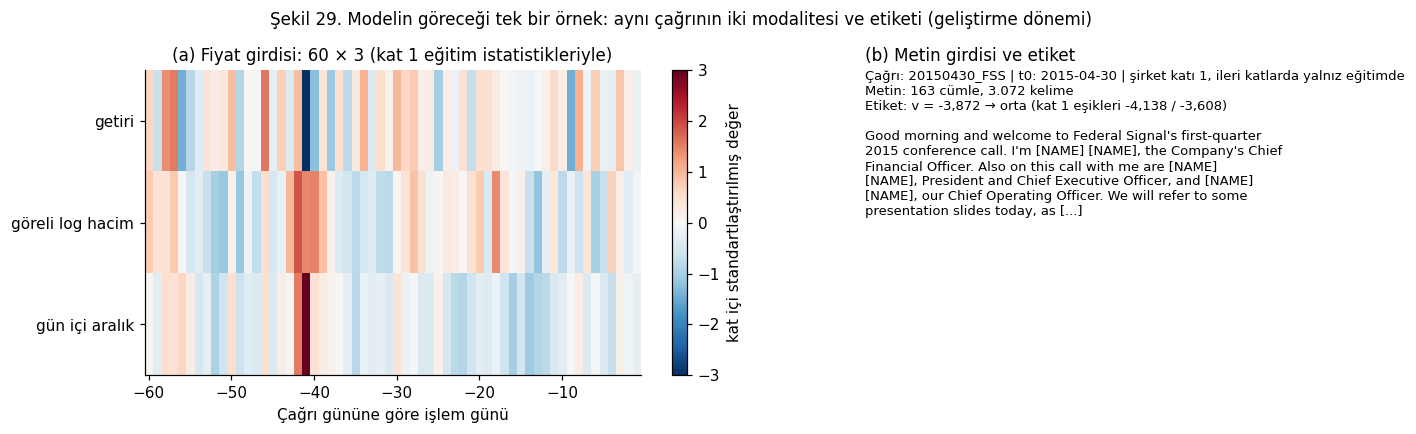

Örnek çağrı (geliştirme medyanına en yakın v, ≥ 1.000 kelime): 20150430_FSS | v = -3.872 | sınıf: orta | 163 cümle, 3072 kelime
Üç kanalın en büyük |z| değerinin görüldüğü gün: -41 (|z| = 3.85) | o gün kanallar: [-3.85  1.45  3.07]


In [10]:
dk_v = b.loc[D, "v"]
aday = b[D & temiz.cumleler_temiz.apply(lambda s: sum(len(x.split()) for x in s) >= 1000).to_numpy()]
i = (aday.v - dk_v.median()).abs().idxmin()
r = b.loc[i]
k = int(r.kat)
egit, dog = bolme.sirket_kati(b, k)
y_d, esik_k = bolme.kat_etiketleri(b, egit, dog)
sinif_i = int(y_d[np.where(b.index[dog] == i)[0][0]])
ornek = (X[i] - X[egit.to_numpy()].mean(axis=(0, 1))) / X[egit.to_numpy()].std(axis=(0, 1))
metin_i = temiz.loc[i, "cumleler_temiz"]

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 3.6), gridspec_kw={"width_ratios": [1.6, 1]})
im = a1.imshow(ornek.T, aspect="auto", cmap="RdBu_r", vmin=-3, vmax=3, extent=[-60.5, -0.5, 2.5, -0.5])
a1.set_yticks([0, 1, 2], ["getiri", "göreli log hacim", "gün içi aralık"])
a1.set_xlabel("Çağrı gününe göre işlem günü")
a1.grid(False)
fig.colorbar(im, ax=a1, label="kat içi standartlaştırılmış değer")
a1.set_title(f"(a) Fiyat girdisi: 60 × 3 (kat {k} eğitim istatistikleriyle)")
a2.axis("off")
ileri_ad = f"ileri kat {int(r.ileri_kat)}" if r.ileri_kat >= 0 else "ileri katlarda yalnız eğitimde"
a2.text(0, 1, f"Çağrı: {r.klasor} | t0: {r.t0.date()} | şirket katı {k}, {ileri_ad}\n"
        f"Metin: {len(metin_i)} cümle, {tr(sum(len(x.split()) for x in metin_i))} kelime\n"
        f"Etiket: v = {tr(r.v, 3)} → {SINIF[sinif_i]} (kat {k} eşikleri {tr(esik_k[0], 3)} / {tr(esik_k[1], 3)})\n\n"
        + textwrap.fill(textwrap.shorten(" ".join(metin_i), 330), 60), va="top", fontsize=8.6)
a2.set_title("(b) Metin girdisi ve etiket", loc="left")
fig.suptitle("Şekil 29. Modelin göreceği tek bir örnek: aynı çağrının iki modalitesi ve etiketi (geliştirme dönemi)", y=1.03, fontsize=11)
kaydet(fig, "f4_04_girdi_ornegi")
plt.show()
print(f"Örnek çağrı (geliştirme medyanına en yakın v, ≥ 1.000 kelime): {r.klasor} | v = {r.v:.3f} | sınıf: {SINIF[sinif_i]} | "
      f"{len(metin_i)} cümle, {sum(len(x.split()) for x in metin_i)} kelime")
gun_z = np.abs(ornek).max(axis=1)
print(f"Üç kanalın en büyük |z| değerinin görüldüğü gün: {int(np.argmax(gun_z)) - 60} (|z| = {gun_z.max():.2f}) | "
      f"o gün kanallar: {np.round(ornek[int(np.argmax(gun_z))], 2)}")

**Ne gözlendi:** Geliştirme dönemi medyanına en yakın hedefli (ve en az 1.000 kelimelik) çağrı Federal Signal (FSS, 2015-04-30): 163 cümle, 3.072 kelime; v = −3,872, kat 1 eşikleriyle (−4,138 / −3,608) orta sınıf. Fiyat girdisinin en uç günü gün −41: getiri −3,85, göreli hacim +1,45, gün içi aralık +3,07 standart sapma (kat içi ölçekte).

**Neden önemli:** Şekil, modelin bir örnekte tam olarak ne göreceğini gösteriyor: aynı çağrıya ait 60 × 3 fiyat dizisi, temizlenmiş metin ve kat eğitiminden hesaplanan eşiklerle atanmış etiket. Kanalların birlikte sıçraması, üç kanalın aynı olayı farklı yönlerden yakaladığını gösteriyor.

**Sonraki aşamaya etkisi:** Final modelinde her örnek bu üçlüyle (dizi, metin, etiket) temsil edilecek; eşleşme bilgisi (`klasor`, `kat`, `ileri_kat`, `bolum`) `bolme.parquet` içinde.

### 5.1 Tek modalite ve füzyon için hazırlık

| Model (final) | Girdi | Amaç |
|---|---|---|
| Taban 1: çoğunluk sınıfı | — | Eksik öğrenmenin alt sınırı (makro-F1 bunun üstünde olmalı) |
| Taban 2: geçmiş oynaklık | `gecmis_oyn_60`, kat eşikleriyle sınıf | Literatürdeki standart taban; fiyat modelinin geçmesi gereken çizgi |
| Yalnız fiyat | 60 × 3 dizi → 1D-CNN ya da küçük LSTM | Fiyat modalitesinin tek başına katkısı |
| Yalnız metin | TF-IDF + lojistik regresyon; dil modeli gömmesi (uzun metin parçalara bölünerek) | Metin modalitesinin tek başına katkısı |
| Erken füzyon | İki modalitenin özellikleri birleştirilip tek sınıflandırıcı | En basit füzyon |
| Geç füzyon | İki tek-modalite modelinin olasılıklarının birleştirilmesi | Modaliteler bağımsız eğitilir |
| Ara füzyon | İki kodlayıcının gömmeleri birleştirilip ortak katman (gerekirse dikkat) | Modaliteler arası etkileşim |
| Ablasyon | Yukarıdakilere sektör ve `piyasa_once` eklenip çıkarılarak | Metnin sektör ötesi katkısı (Faz 3 Bölüm 9) |

**Giderilmesi gereken veri sorunları:** uzun metinler (dil modelinin girdi sınırı için parçalama), eşiğe yakın belirsiz
etiketler (geliştirme döneminde %23,6; sürekli `v` ile regresyon da raporlanacak), sektörü bilinmeyen çağrılar (ablasyonda
"bilinmiyor" ayrı kategori), açılış öncesi / kapanış sonrası çağrı karışıklığı (kural C ile hedefte), testte 135 yeni şirket
(ayrı raporlanacak), metni olmayan 26 çağrı (eksik modalite; ana veri setinde yok).

## 6. Aşırı ve eksik öğrenmeyi izleme planı (final aşaması için)

| Ne | Nasıl | Hangi işaret |
|---|---|---|
| Aşırı öğrenme | Her katta eğitim ve doğrulama makro-F1'i yan yana; öğrenme eğrisi (eğitim kümesi %25/50/75/100) | Eğitim skoru yüksek, doğrulama düşük ve fark büyüyor |
| Eksik öğrenme | Tabanlarla karşılaştırma (çoğunluk sınıfı, geçmiş oynaklık) | Model tabanları geçemiyor ya da eğitim skoru da düşük |
| Kararlılık | 5 şirket katının ortalama ± standart sapması; ileri katlar | Katlar arası büyük oynama |
| Önlemler | Erken durdurma (doğrulama kaybı), ağırlık azaltma / dropout, küçük model, sınıf dengesi | — |
| Seçim yanlılığı | Hiperparametre yalnız geliştirme katlarıyla; test bir kez | Test skorunun katlardan belirgin düşük çıkması (zaman kayması) |

Ölçütler test dağılımına bakılmadan önceden belirlenmiştir: **makro-F1** (ana), sınıf başına kesinlik/duyarlılık, karışıklık
matrisi; yardımcı olarak sürekli `v` için ortalama mutlak hata.

## 7. Kısa değerlendirme

**Yapılanlar**
1. Zamanca ayrı bir test kümesi (2017-01-17 → 2018-06, 1.134 çağrı) ayrıldı; geliştirme ile test arasında 55 takvim günlük
   doğal boşluk var, arındırılacak çağrı çıkmadı. Testte 135 yeni şirket (219 çağrı) ayrıca raporlanabilecek.
2. Geliştirme döneminde iki doğrulama düzeni kuruldu: şirkete göre gruplu, sınıf oranı korunan 5 kat (ortak şirket 0, her
   katta ~125 / 125 / 125) ve 2016'nın dört çeyreği için ileri katlar (arındırmayla).
3. Sızıntı denetimi: şirket ayrımı tam; çoklu kodlu şirket yok; metin kopyası yok; ancak şirket katlarında doğrulama
   çağrılarının %99,5'i eğitimle aynı haftaları paylaşıyor → zaman ayrımı için ileri katlar ve test şart.
4. Her modalitenin girdi biçimi ve kat içi ön işleme (standartlaştırma, TF-IDF, eşik) örnekle gösterildi.

**Sınırlılıklar:** CIK'i bilinmeyen %22,3 çağrıda aynı şirketin farklı kodla gelmesi kontrol edilemiyor; ileri katların
doğrulama kümeleri küçük (181–392 çağrı) ve piyasa dönemine göre sınıf dağılımları farklı.

**Final için hazır olanlar:** `bolme.parquet`, `seri_girdisi.npz`, `temiz_cagrilar.parquet`, `src/bolme.py`; taban ve füzyon
modellerinin listesi (§5.1); aşırı/eksik öğrenme izleme planı (§6).